In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import re

# **EDA**

In [ ]:
# STEP 1: DATA UNDERSTANDING

# Load data
df = pd.read_csv('/content/drive/MyDrive/Copy of Training_data_2.csv')

# Basic structure
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

Shape: (105710, 2)

Columns: ['News Headline', 'News Topic']


**Training data has Rows: 105,710 and Columns: 2 where News Headline (input text) and News Topic (target label).**

In [ ]:
# Rename columns (for convenience)
df.columns = ["headline", "topic"]

# Data types
print("\nData Types:\n", df.dtypes)

# Preview
print("\nSample Data:\n", df.head())


Data Types:
 headline    object
topic       object
dtype: object

Sample Data:
                                             headline                   topic
0  <html> <body> News Headlines:\n <br> <b> US In...                Business
1  <html> <body> News Headlines:\n <br> <b> Repor...                Business
2  <html> <body> News Headlines:\n <br> <b> PITCA...              World News
3  <html> <body> News Headlines:\n <br> <b> Unoca...                Business
4  <html> <body> News Headlines:\n <br> <b> Mac B...  Science and Technology


We observed inconsistencies in both the text and labels that could negatively affect model training, such as extra punctuation (e.g., “Science and Technology,”), trailing spaces, duplicate class names (e.g., “Business” vs “Business ”) and unnecessary HTML tags in the input text. To address this, we cleaned the dataset by removing HTML tags and irrelevant prefixes like “News Headlines:” to retain only the actual content, while labels were standardized by stripping whitespace, removing punctuation, and normalizing category names to ensure consistency across all classes.

In [ ]:
# STEP 2: MINIMAL CLEANING

# Function to remove HTML tags
def clean_html(text):
    text = re.sub(r'<.*?>', ' ', str(text))
    text = re.sub(r'News Headlines:', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Apply cleaning to headline
df["headline_clean"] = df["headline"].apply(clean_html)
print(df["headline_clean"])

# Clean topic labels
df["topic_clean"] = df["topic"].str.strip()\
                               .str.replace(",", "", regex=False)\
                               .str.title()
print(df["topic_clean"])

0         US Interest Rates Boosted for Third Straight M...
1         Report on Fannie Mae Regulator a Secret The in...
2         PITCAIRN: SIX GUILTY OF SEX CRIMES Six men on ...
3         Unocal to Settle Myanmar Lawsuits Unocal Corp....
4         Mac Bumps Mail, iDisk Storage to 250MB Apple C...
                                ...                        
105705    Small Plane Crashes in China, Killing 54 Rescu...
105706    Israel softens UN ambulance claim Israel revie...
105707    Fannie Mae Told to Restate Earnings An officia...
105708    UN pledges help for Darfur refugees, Sudan wan...
105709    Nice Witch of the North Comedienne Shabana Reh...
Name: headline_clean, Length: 105710, dtype: object
0                       Business
1                       Business
2                     World News
3                       Business
4         Science And Technology
                   ...          
105705                World News
105706                World News
105707                  

We identified duplicate rows in the dataset, which could bias the model by over-representing repeated patterns, so they were removed to ensure fair training. We also observed class imbalance, which can lead to biased classifiers and misleading accuracy scores, making evaluation metrics like F1-score more reliable. Additionally, the texts are long (typically 30–40 words),which increases vocabulary diversity and leads to high-dimensional and sparse feature representations when using bag-of-words approaches. To address this, TF-IDF with n-grams was employed to capture both term importance and contextual relationships between words.

In [ ]:
# STEP 2A: MISSING VALUES

print("\nMissing Values:\n", df.isnull().sum())

# STEP 2B: DUPLICATE CHECK

duplicates = df.duplicated(subset=["headline_clean", "topic_clean"]).sum()
print("\nNumber of duplicate rows:", duplicates)

#  Remove duplicates
df_clean = df.drop_duplicates(subset=["headline_clean", "topic_clean"])

print("Shape after removing duplicates:", df_clean.shape)



Missing Values:
 headline          0
topic             0
headline_clean    0
topic_clean       0
dtype: int64

Number of duplicate rows: 22015
Shape after removing duplicates: (83695, 4)


In [ ]:
print(df.head())

                                            headline                   topic  \
0  <html> <body> News Headlines:\n <br> <b> US In...                Business   
1  <html> <body> News Headlines:\n <br> <b> Repor...                Business   
2  <html> <body> News Headlines:\n <br> <b> PITCA...              World News   
3  <html> <body> News Headlines:\n <br> <b> Unoca...                Business   
4  <html> <body> News Headlines:\n <br> <b> Mac B...  Science and Technology   

                                      headline_clean             topic_clean  
0  US Interest Rates Boosted for Third Straight M...                Business  
1  Report on Fannie Mae Regulator a Secret The in...                Business  
2  PITCAIRN: SIX GUILTY OF SEX CRIMES Six men on ...              World News  
3  Unocal to Settle Myanmar Lawsuits Unocal Corp....                Business  
4  Mac Bumps Mail, iDisk Storage to 250MB Apple C...  Science And Technology  


In [ ]:
# STEP 2C: BASIC TEXT STATS

# Word count
df_clean["word_count"] = df_clean["headline_clean"].apply(lambda x: len(x.split()))

# Character count
df_clean["char_count"] = df_clean["headline_clean"].apply(len)

print("\nWord Count Stats:\n", df_clean["word_count"].describe())
print("\nCharacter Count Stats:\n", df_clean["char_count"].describe())


Word Count Stats:
 count    83695.000000
mean        37.800096
std         10.187119
min          8.000000
25%         32.000000
50%         37.000000
75%         43.000000
max        171.000000
Name: word_count, dtype: float64

Character Count Stats:
 count    83695.000000
mean       237.491212
std         67.964401
min         99.000000
25%        197.000000
50%        233.000000
75%        267.000000
max       1009.000000
Name: char_count, dtype: float64


/tmp/ipykernel_2636/2130781159.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["word_count"] = df_clean["headline_clean"].apply(lambda x: len(x.split()))
/tmp/ipykernel_2636/2130781159.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["char_count"] = df_clean["headline_clean"].apply(len)


The dataset shows an average word count of approximately 38 words, with values ranging from 8 to 171 words and a median of about 37 words. This is an important finding because it does not match the typical structure of news headlines, which usually contain only 5–15 words. Instead, the data likely consists of aggregated headline blocks, headline-plus-summary entries, or merged text segments, as suggested by the unusually high mean and long maximum length.
This has important implications for modeling. Since the texts are longer than standard headlines, they contain richer vocabulary, making TF-IDF with n-grams more effective than in typical short-text scenarios. It also shifts the problem closer to document classification rather than simple headline classification. As a result, using bigrams/trigrams and dimensionality reduction techniques like SVD becomes more suitable for feature handling.
Finally, the presence of a long right tail (up to 171 words) indicates possible noise or inconsistent formatting, including residual HTML artifacts or merged entries, which justifies additional preprocessing and filtering steps.

In [ ]:
# STEP 2D: UNIQUE LABELS

print("\nUnique Topics:", df_clean["topic_clean"].nunique())
print("\nTopic Distribution:\n", df_clean["topic_clean"].value_counts())

# SAVE CLEAN DATA (IMPORTANT)

df_clean.to_csv("cleaned_news_data.csv", index=False)

print("\nCleaned dataset saved as 'cleaned_news_data.csv'")


Unique Topics: 4

Topic Distribution:
 topic_clean
Business                  26539
Science And Technology    23666
World News                21740
Sports                    11750
Name: count, dtype: int64

Cleaned dataset saved as 'cleaned_news_data.csv'


In [ ]:
import matplotlib.pyplot as plt

# STEP 3A: CLASS DISTRIBUTION

topic_counts = df_clean["topic_clean"].value_counts()

print("\nClass Distribution:\n", topic_counts)


Class Distribution:
 topic_clean
Business                  26539
Science And Technology    23666
World News                21740
Sports                    11750
Name: count, dtype: int64


In [ ]:
# STEP 3B: PERCENTAGE DISTRIBUTION

topic_percent = df_clean["topic_clean"].value_counts(normalize=True) * 100

print("\nClass Percentage (%):\n", topic_percent)


Class Percentage (%):
 topic_clean
Business                  31.709182
Science And Technology    28.276480
World News                25.975267
Sports                    14.039070
Name: proportion, dtype: float64


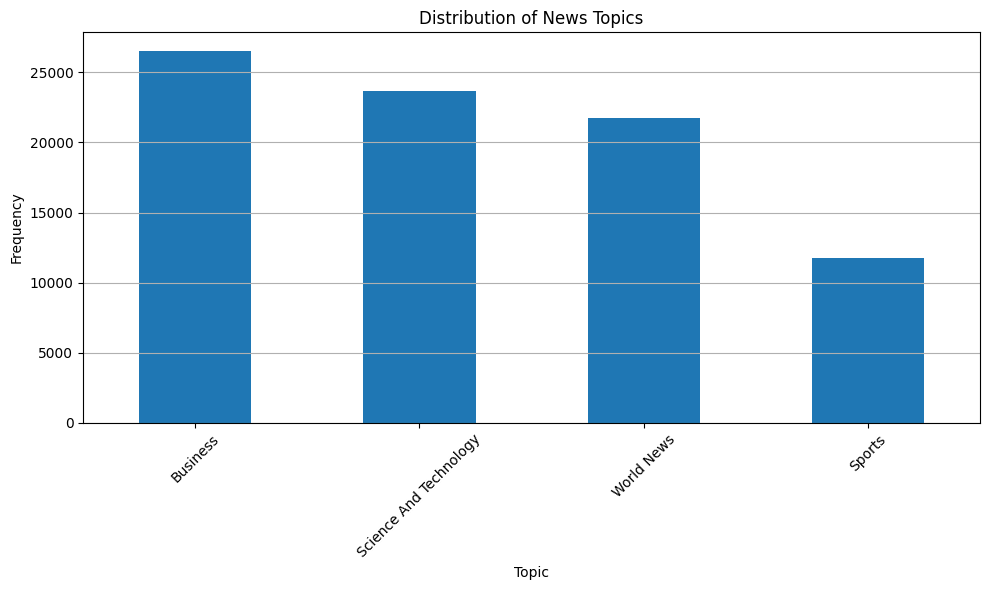

In [ ]:
# STEP 3C: VISUALIZATION (BAR PLOT)

plt.figure(figsize=(10,6))
topic_counts.plot(kind="bar")

plt.title("Distribution of News Topics")
plt.xlabel("Topic")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

The imbalance ratio is calculated as the size of the smallest class divided by the size of the largest class. Based on standard interpretation, a ratio below 1.5 indicates a balanced dataset, between 1.5 and 3 indicates moderate imbalance and above 3 suggests severe imbalance (He & Garcia, 2009). In imbalanced settings, models tend to favor majority classes, making accuracy misleading and often hiding poor performance on minority classes.
To handle this, different strategies are recommended depending on the model type. For classical machine learning methods like Logistic Regression or SVM with TF-IDF features, using class_weight='balanced' helps reduce bias. For deep learning models such as LSTM or BERT, weighted loss functions or focal loss can improve minority class learning. Data-level techniques like oversampling (e.g., SMOTE) or undersampling can also be applied, though SMOTE is often less effective for text data and undersampling may discard useful information.
In this specific case, the effect of imbalance is more pronounced because the texts are short and contain limited contextual information, making minority classes harder to distinguish reliably.

In [ ]:
# STEP 3D: IMBALANCE RATIO

max_class = topic_counts.max()
min_class = topic_counts.min()

imbalance_ratio = max_class / min_class

print("\nImbalance Ratio (Max / Min):", round(imbalance_ratio, 2))


Imbalance Ratio (Max / Min): 2.26


The largest class is approximately 2.26 times bigger than the smallest class, which indicates a moderate but not severe imbalance. While this level of imbalance is generally acceptable for models like Logistic Regression, SVM and Naive Bayes, it is still important to account for its effects during training. In practice, the model may show a slight bias toward the majority class, which can lead to reduced recall for minority classes even if overall accuracy appears strong.


In [ ]:
df_clean[df_clean["word_count"] > 100]["headline_clean"].head(5)

,headline_clean
604,House Bill HR 10 permits sending certain suspe...
2924,No Confidence Vote Passes Against UN Top Leade...
3323,You Control: iTunes puts control in OS X menu ...
5122,Russia Combines Oil and Gas (The Motley Fool) ...
5724,"Thousands March to Holy Shrine in Najaf NAJAF,..."


In [ ]:
print(df_clean["word_count"])

0         48
1         47
2         30
3         34
4         33
          ..
105700    38
105702    37
105703    38
105704    32
105707    39
Name: word_count, Length: 83695, dtype: int64


In [ ]:
# Inspect very long texts
long_texts = df_clean[df_clean["word_count"] > 100]
print(long_texts)

                                                 headline  \
604     <html> <body> News Headlines:\n <br> <b> House...   
2924    <html> <body> News Headlines:\n <br> <b> No Co...   
3323    <html> <body> News Headlines:\n <br> <b> You C...   
5122    <html> <body> News Headlines:\n <br> <b> Russi...   
5724    <html> <body> News Headlines:\n <br> <b> Thous...   
...                                                   ...   
102326  <html> <body> News Headlines:\n <br> <b> Bush ...   
103045  <html> <body> News Headlines:\n <br> <b> Plea ...   
103301  <html> <body> News Headlines:\n <br> <b> Analy...   
105336  <html> <body> News Headlines:\n <br> <b> China...   
105466  <html> <body> News Headlines:\n <br> <b> The V...   

                         topic  \
604     Science and Technology   
2924    Science and Technology   
3323    Science and Technology   
5122    Science and Technology   
5724                World News   
...                        ...   
102326  Science and Technolog

In [ ]:
print("Number of very long samples:", long_texts.shape[0])
print("\nSample long texts:\n")

for i, row in long_texts.head(5).iterrows():
    print(f"--- Sample {i} ---")
    print(row["headline_clean"])
    print("\n")

Number of very long samples: 149

Sample long texts:

--- Sample 604 ---
House Bill HR 10 permits sending certain suspects abroad for torture? Tucked away in Section 3032 and 3033 of H.R. 10, the 9/11 Recommendations Implementation Act of 2004, is an "anti-terrorist" provision that was never recommended by the 9/11 Commission. Indeed, it is the very opposite of a Commission recommendation - as noted in a critical press release about the bill from Rep. Edward Markey (D-MA), quoted here. The bill was introduced by House Speaker Dennis Hastert (R-IL). This provision retroactively establishes a loophole legitimising the practice of extraditing "suspected terrorists" to another country where torture is legal or unprosecuted, for the purpose of having them tortured there.


--- Sample 2924 ---
No Confidence Vote Passes Against UN Top Leadership Already embattled with his ties to the Iraqi Oil for Food scandal, and what some term as the 'Food for Sex' scandal, Kofi Annan has dodged the latest

In [ ]:
# Inspect very short texts
short_texts = df_clean[df_clean["word_count"] < 10]

print("Number of very short samples:", short_texts.shape[0])
print("\nSample short texts:\n")

for i, row in short_texts.head(5).iterrows():
    print(f"--- Sample {i} ---")
    print(row["headline_clean"])
    print("\n")

Number of very short samples: 5

Sample short texts:

--- Sample 35538 ---
&lt;cite&gt;Register&lt;/cite&gt; restores ad service &lt;strong&gt;Site Notice&lt;/strong&gt; Some rough figures


--- Sample 38710 ---
WIZARDSINSIDER WHO'S NEXT? &lt;br&gt;at Lakers&lt;br&gt;Friday, 10:30 p.m.&lt;br&gt;Comcast SportsNet


--- Sample 71859 ---
The PeopleSoft vs. Oracle clash &lt;strong&gt;A &lt;cite&gt;Register&lt;/cite&gt; History&lt;/strong&gt;


--- Sample 72598 ---
Stocks to Watch ORACLE CORP. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=ORCL.O target=/stocks/quickinfo/fullquote"&gt;ORCL.O&lt;/A&gt;:


--- Sample 87579 ---
Stocks to Watch Wednesday COCA-COLA CO. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=KO.N target=/stocks/quickinfo/fullquote"&gt;KO.N&lt;/A&gt;:




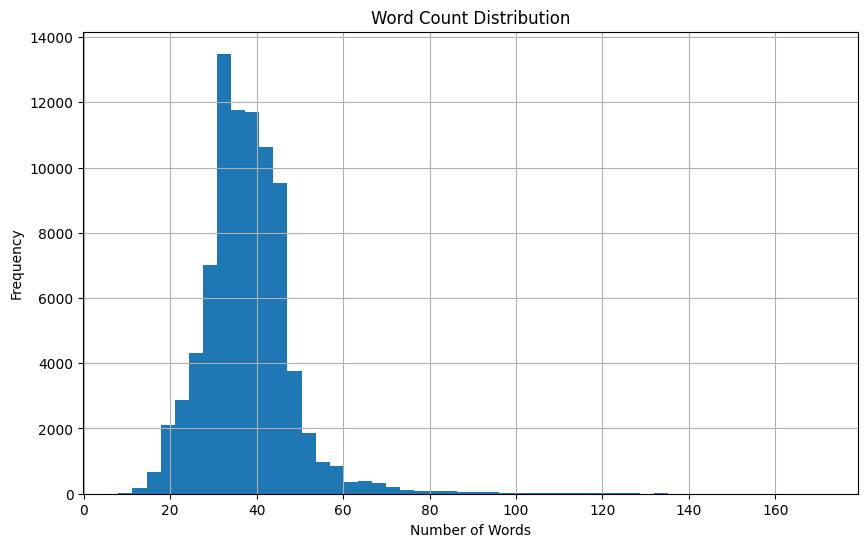

In [ ]:
# Histogram of word count distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.hist(df_clean["word_count"], bins=50)

plt.title("Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.grid()
plt.show()

The word count distribution is right-skewed, with most texts peaking around 30–40 words. Based on this observation, entries with very low or very high lengths were treated as anomalies, particularly those outside the 10 to 100 word range. Extremely long texts (greater than 100 words) were removed to reduce noise, while very short texts were also excluded as they contribute limited contextual information for learning and do not significantly improve model performance.

In [ ]:
df_filtered = df_clean[
    (df_clean["word_count"] >= 10) &
    (df_clean["word_count"] <= 100)
].copy()

print("New shape after filtering:", df_filtered.shape)

New shape after filtering: (83541, 6)


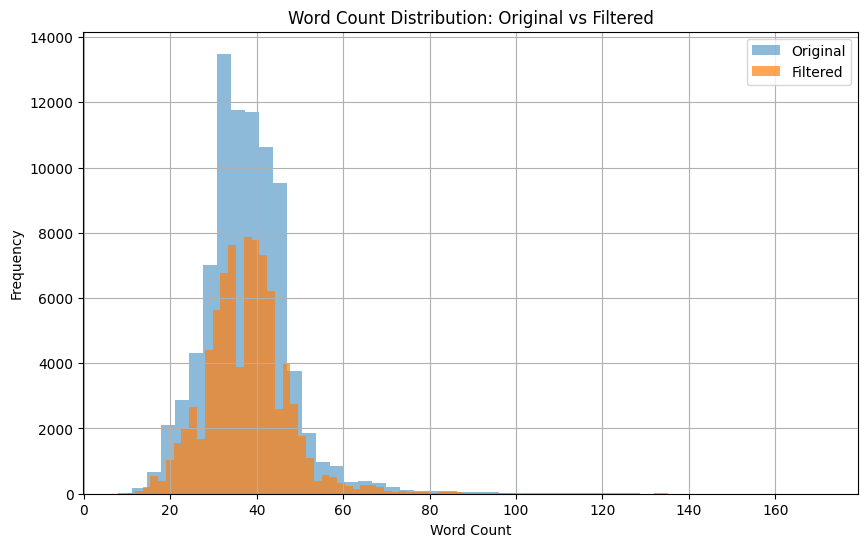

/tmp/ipykernel_3828/3269819472.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


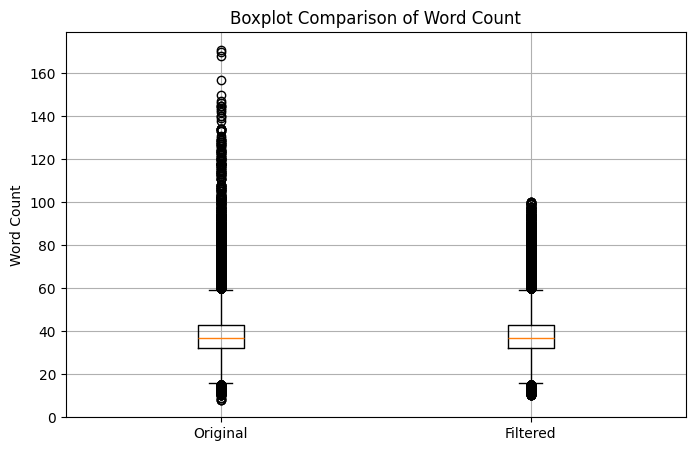


Original Word Count Stats:
 count    83695.000000
mean        37.800096
std         10.187119
min          8.000000
25%         32.000000
50%         37.000000
75%         43.000000
max        171.000000
Name: word_count, dtype: float64

Filtered Word Count Stats:
 count    83541.000000
mean        37.657091
std          9.579480
min         10.000000
25%         32.000000
50%         37.000000
75%         43.000000
max        100.000000
Name: word_count, dtype: float64


In [ ]:
# 1. HISTOGRAM COMPARISON

plt.figure(figsize=(10,6))

plt.hist(df_clean["word_count"], bins=50, alpha=0.5, label="Original")
plt.hist(df_filtered["word_count"], bins=50, alpha=0.7, label="Filtered")

plt.title("Word Count Distribution: Original vs Filtered")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.legend()
plt.grid()

plt.show()

# 2. BOXPLOT COMPARISON

plt.figure(figsize=(8,5))

plt.boxplot(
    [df_clean["word_count"], df_filtered["word_count"]],
    labels=["Original", "Filtered"]
)

plt.title("Boxplot Comparison of Word Count")
plt.ylabel("Word Count")
plt.grid()

plt.show()
# 3. SUMMARY STATISTICS COMPARISO

print("\nOriginal Word Count Stats:\n", df_clean["word_count"].describe())
print("\nFiltered Word Count Stats:\n", df_filtered["word_count"].describe())

After removing outliers with very long text lengths, the histogram shows a more stabilized and well-balanced distribution, with the long right tail significantly reduced. Similarly, in the boxplot, the extreme whiskers have been minimized, indicating that the dataset now has fewer extreme values and a more consistent spread of word counts, leading to cleaner and more reliable input for modeling.

**TEXT EDA**

In [ ]:
# Tokenization
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Lowercase (for EDA only)
df_filtered["text_lower"] = df_filtered["headline_clean"].str.lower()

# Tokenization (simple split)
df_filtered["tokens"] = df_filtered["text_lower"].apply(lambda x: x.split())

print(df_filtered["tokens"])

0         [us, interest, rates, boosted, for, third, str...
1         [report, on, fannie, mae, regulator, a, secret...
2         [pitcairn:, six, guilty, of, sex, crimes, six,...
3         [unocal, to, settle, myanmar, lawsuits, unocal...
4         [mac, bumps, mail,, idisk, storage, to, 250mb,...
                                ...                        
105700    [president, oks, overhaul, of, corporate, tax,...
105702    [fedex, earnings, more, than, double, new, yor...
105703    [arab-owned, israeli, team, faces, up, to, sou...
105704    [sony, launches, music, players, with, mp3, su...
105707    [fannie, mae, told, to, restate, earnings, an,...
Name: tokens, Length: 83541, dtype: object


In [ ]:
# VOCAB SIZE & RICHNESS

all_words = [word for tokens in df_filtered["tokens"] for word in tokens]

vocab = set(all_words)

print("Total Words:", len(all_words))
print("Unique Words (Vocabulary Size):", len(vocab))
print("Vocabulary Density:", len(vocab) / len(all_words))

Total Words: 3145911
Unique Words (Vocabulary Size): 129286
Vocabulary Density: 0.041096521802428614


In [ ]:
# MOST FREQUENT WORDS W/O STOPWORDS

from collections import Counter

word_counts = Counter(all_words)

print("\nTop 20 Most Common Words (Raw):")
print(word_counts.most_common(20))


Top 20 Most Common Words (Raw):
[('the', 135839), ('to', 83056), ('a', 74434), ('of', 69421), ('in', 65532), ('and', 48007), ('on', 39901), ('for', 34113), ('-', 27308), ('#39;s', 21237), ('that', 19969), ('as', 17796), ('with', 17487), ('its', 17340), ('at', 15980), ('new', 15404), ('is', 15312), ('by', 14868), ('it', 13579), ('has', 13324)]


In [ ]:
# MOST FREQUENT WORDS W/ STOPWORDS

filtered_words = [
    word for word in all_words
    if word not in ENGLISH_STOP_WORDS and word.isalpha()
]

word_counts_clean = Counter(filtered_words)

print("\nTop 20 Most Common Words (Cleaned):")
print(word_counts_clean.most_common(20))


Top 20 Most Common Words (Cleaned):
[('new', 15404), ('said', 12971), ('oil', 6011), ('company', 5001), ('ap', 4784), ('microsoft', 4301), ('world', 4275), ('president', 4079), ('york', 4041), ('prices', 3688), ('million', 3656), ('says', 3617), ('monday', 3613), ('tuesday', 3494), ('iraq', 3469), ('thursday', 3445), ('wednesday', 3430), ('reuters', 3366), ('united', 3363), ('government', 3287)]


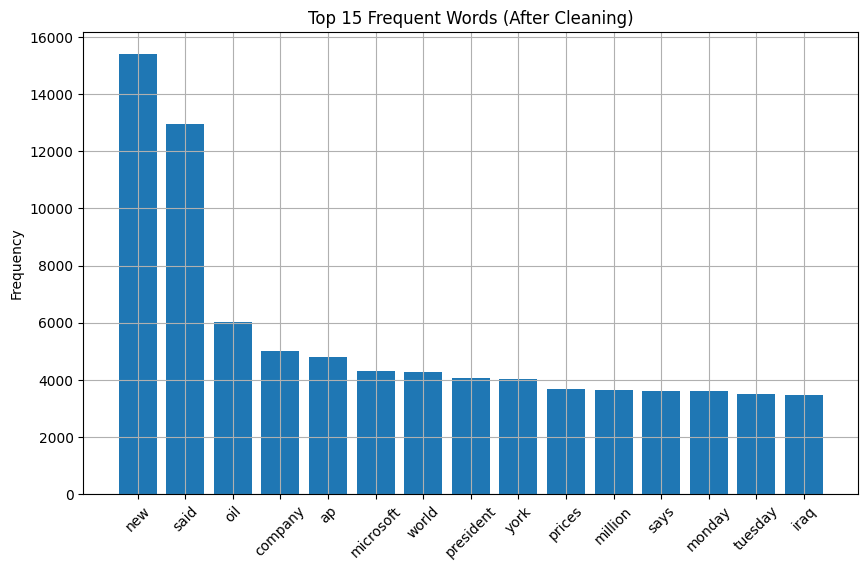

In [ ]:
# VISULIZATION OF TOP WORDS

import matplotlib.pyplot as plt

top_words = word_counts_clean.most_common(15)
words, counts = zip(*top_words)

plt.figure(figsize=(10,6))
plt.bar(words, counts)

plt.title("Top 15 Frequent Words (After Cleaning)")
plt.xticks(rotation=45)
plt.ylabel("Frequency")

plt.grid()
plt.show()

In [ ]:
# VISULIZATION OF TOP WORDS (TOPIC WISE)

topic_groups = df_filtered.groupby("topic_clean")

for topic, group in topic_groups:
    words = [word for tokens in group["tokens"] for word in tokens]

    words = [
        w for w in words
        if w not in ENGLISH_STOP_WORDS and w.isalpha()
    ]

    counter = Counter(words)

    print(f"\nTop words for topic: {topic}")
    print(counter.most_common(10))


Top words for topic: Business
[('said', 5907), ('new', 5841), ('oil', 5338), ('prices', 3285), ('company', 2938), ('york', 2712), ('percent', 2536), ('stocks', 2194), ('sales', 2184), ('profit', 2154)]

Top words for topic: Science And Technology
[('new', 5486), ('microsoft', 3645), ('said', 2550), ('software', 2461), ('internet', 2250), ('company', 1857), ('space', 1673), ('search', 1652), ('computer', 1631), ('music', 1584)]

Top words for topic: Sports
[('new', 1612), ('win', 1248), ('ap', 1211), ('game', 1206), ('team', 1151), ('world', 1149), ('cup', 993), ('league', 948), ('victory', 912), ('coach', 800)]

Top words for topic: World News
[('said', 3996), ('iraq', 3158), ('president', 2885), ('new', 2465), ('minister', 2228), ('killed', 2175), ('ap', 2051), ('iraqi', 1758), ('government', 1691), ('prime', 1683)]


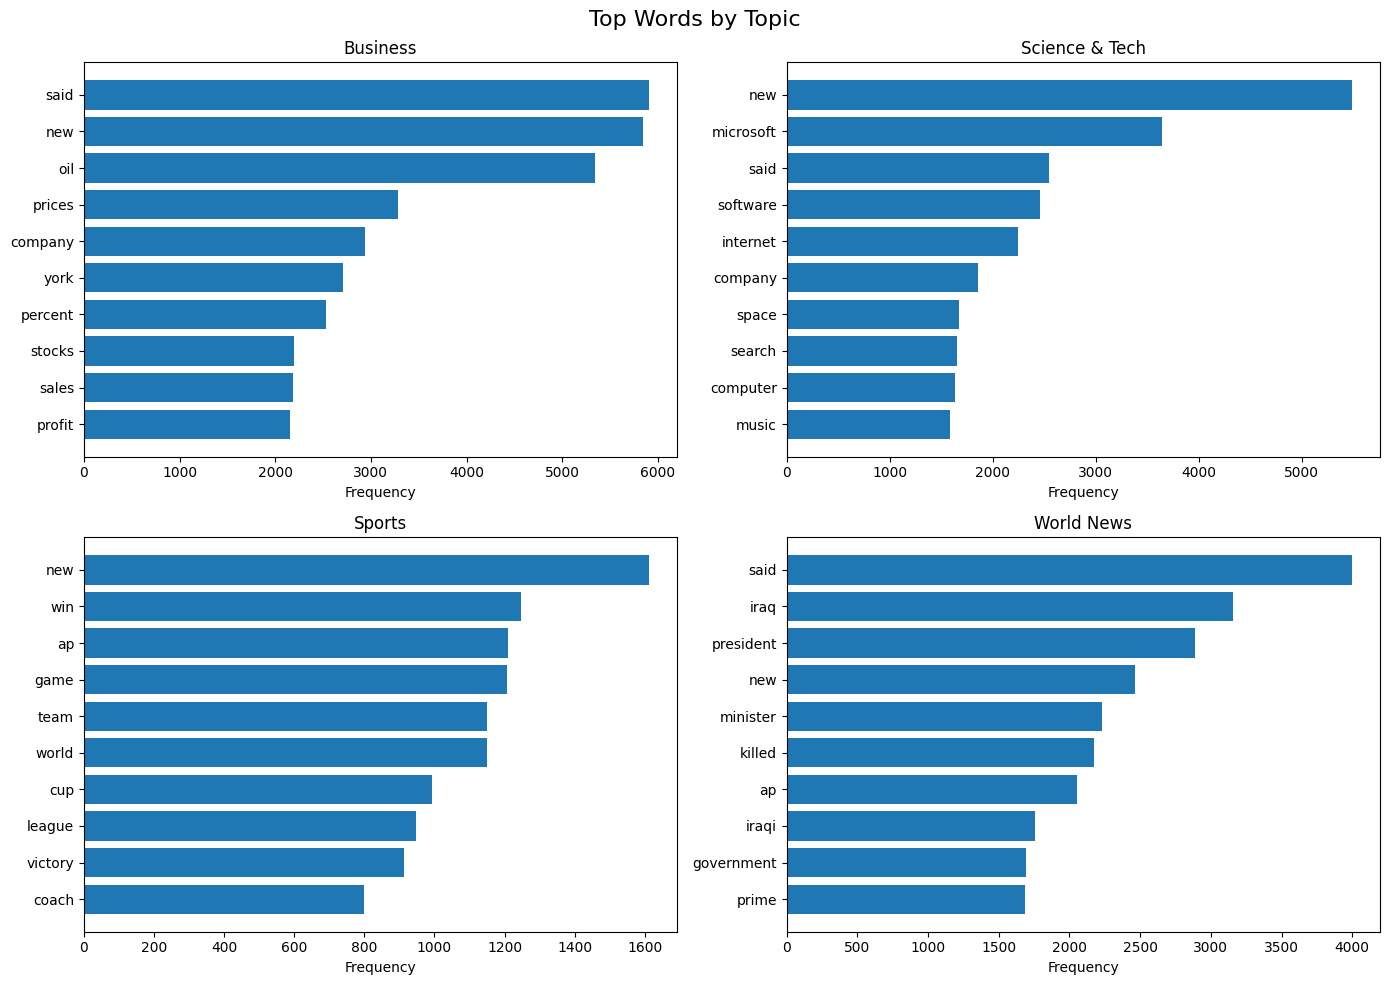

In [ ]:
import matplotlib.pyplot as plt


topic_words = {
    "Business": [('said', 5907), ('new', 5841), ('oil', 5338), ('prices', 3285),
                 ('company', 2938), ('york', 2712), ('percent', 2536),
                 ('stocks', 2194), ('sales', 2184), ('profit', 2154)],

    "Science & Tech": [('new', 5486), ('microsoft', 3645), ('said', 2550),
                       ('software', 2461), ('internet', 2250), ('company', 1857),
                       ('space', 1673), ('search', 1652), ('computer', 1631),
                       ('music', 1584)],

    "Sports": [('new', 1612), ('win', 1248), ('ap', 1211), ('game', 1206),
               ('team', 1151), ('world', 1149), ('cup', 993), ('league', 948),
               ('victory', 912), ('coach', 800)],

    "World News": [('said', 3996), ('iraq', 3158), ('president', 2885),
                   ('new', 2465), ('minister', 2228), ('killed', 2175),
                   ('ap', 2051), ('iraqi', 1758), ('government', 1691),
                   ('prime', 1683)]
}



fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.flatten()

for ax, (topic, words) in zip(axes, topic_words.items()):
    w, c = zip(*words)

    ax.barh(w, c)
    ax.set_title(topic)
    ax.invert_yaxis()
    ax.set_xlabel("Frequency")

plt.suptitle("Top Words by Topic", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# BIGRAMS

from nltk.util import ngrams

bigrams = list(ngrams(filtered_words, 2))

bigram_counts = Counter(bigrams)

print("\nTop 15 Bigrams:")
print(bigram_counts.most_common(15))


Top 15 Bigrams:
[(('new', 'york'), 4006), (('oil', 'prices'), 2150), (('prime', 'minister'), 1624), (('united', 'states'), 1379), (('wall', 'street'), 880), (('chief', 'executive'), 840), (('san', 'francisco'), 799), (('president', 'bush'), 658), (('crude', 'oil'), 619), (('united', 'nations'), 593), (('said', 'monday'), 575), (('said', 'thursday'), 558), (('european', 'union'), 556), (('los', 'angeles'), 546), (('said', 'tuesday'), 531)]


In [ ]:
# TRIGRAMS

from nltk.util import ngrams

trigrams = list(ngrams(filtered_words, 3))

trigram_counts = Counter(trigrams)

print("\nTop 15 Trigrams:")
print(trigram_counts.most_common(15))


Top 15 Trigrams:
[(('new', 'york', 'stocks'), 408), (('prime', 'minister', 'ariel'), 264), (('securities', 'exchange', 'commission'), 254), (('crude', 'oil', 'prices'), 212), (('delta', 'air', 'lines'), 212), (('prime', 'minister', 'tony'), 210), (('minister', 'ariel', 'sharon'), 199), (('president', 'vladimir', 'putin'), 195), (('minister', 'tony', 'blair'), 187), (('president', 'george', 'bush'), 171), (('international', 'space', 'station'), 168), (('boston', 'red', 'sox'), 165), (('secretary', 'state', 'colin'), 156), (('new', 'york', 'yankees'), 155), (('london', 'oil', 'prices'), 148)]


Bigrams and trigrams capture context but trigrams  are too sparse for the given dataset size

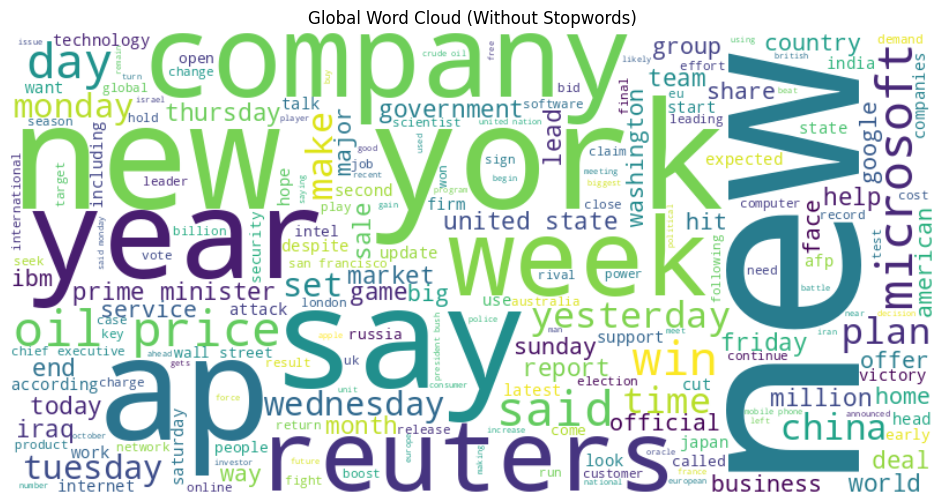

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Join all filtered words into one string
text_all = " ".join(filtered_words)

# Generate word cloud
wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=200
).generate(text_all)

# Plot
plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.title("Global Word Cloud (Without Stopwords)")
plt.show()

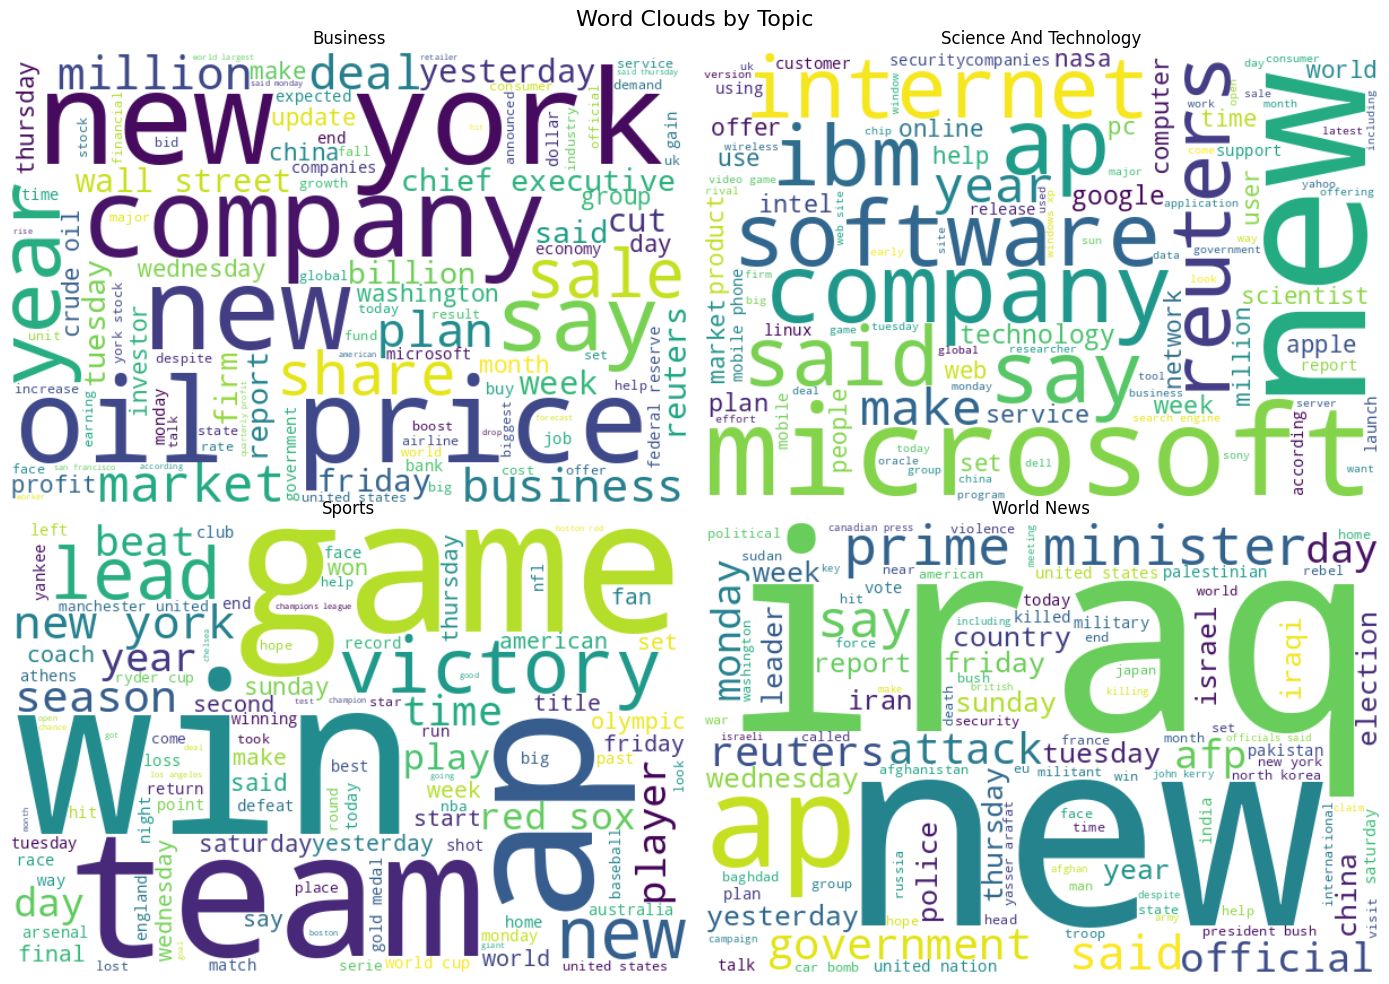

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.flatten()

for ax, (topic, group) in zip(axes, df_filtered.groupby("topic_clean")):

    words = [
        word for tokens in group["tokens"] for word in tokens
        if word not in ENGLISH_STOP_WORDS and word.isalpha()
    ]

    text = " ".join(words)

    wc = WordCloud(
        width=600,
        height=400,
        background_color='white',
        max_words=100
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(topic)
    ax.axis("off")

plt.suptitle("Word Clouds by Topic", fontsize=16)
plt.tight_layout()
plt.show()

**DATASET DIVISION AND PREPROCESSING**

In [ ]:
df_base = df.copy()

In [ ]:
# NO PREPROCESSED DATASET

df_no_prep = df_base.copy()
df_no_prep["text"] = df_no_prep["headline"]

In [ ]:
df_base["word_count"] = df_base["headline"].apply(lambda x: len(str(x).split()))

df_base = df_base[
    (df_base["word_count"] >= 10) &
    (df_base["word_count"] <= 100)
].copy()

In [ ]:
# EXTREME PREPROCESSING

from nltk.stem import LancasterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
ls = LancasterStemmer()

def extreme_clean(text):
    text = re.sub(r'<.*?>', ' ', str(text))
    text = text.lower()
    text = re.sub(r'[^a-zA-Z]', ' ', text)

    words = text.split()
    words = [w for w in words if w not in ENGLISH_STOP_WORDS]
    words = [ls.stem(w) for w in words]
    words = [w for w in words if len(w) > 2]

    return " ".join(words)

df_extreme = df_base.copy()
df_extreme["text"] = df_extreme["headline"].apply(extreme_clean)

Stopword removal typically eliminates common words like “the” and “is,” which is generally useful in NLP tasks. However, in this dataset, TF-IDF already handles this by naturally downweighting frequent terms, making additional stopword removal largely redundant. On the other hand, using isalpha() removes punctuation and numeric tokens, which can unintentionally discard meaningful information such as “U.S.” (converted incorrectly to “us”), “9/11” (completely removed), and “S&P” (lost entirely). As a result, this step may remove important signals that are actually useful for classification.

In [ ]:
# OPTIMAL PREPROCESSING

def optimal_clean(text):
    text = text.lower()

    text = re.sub(r'<.*?>', ' ', text)

    text = re.sub(r'[^\w\s]', ' ', text)

    words = text.split()

    words = [w for w in words if w.isalpha()]

    words = [w for w in words if len(w) > 2]

    return " ".join(words)

df_optimal = df_base.copy()
df_optimal["text"] = df_optimal["headline"].apply(optimal_clean)

In [ ]:
print(df_no_prep["text"].head(1))
print(df_extreme["text"].head(1))
print(df_optimal["text"].head(1))

0    <html> <body> News Headlines:\n <br> <b> US In...
Name: text, dtype: object
0    new headlin rat boost straight mon cent bank f...
Name: text, dtype: object
0    news headlines interest rates boosted for thir...
Name: text, dtype: object


In [ ]:
df_test = pd.read_csv('/content/drive/MyDrive/Copy of Test_data.csv')
df_test.columns = ["headline", "topic"]

df_test_no = df_test.copy()
df_test_no["text"] = df_test_no["headline"]

df_test_ext = df_test.copy()
df_test_ext["text"] = df_test_ext["headline"].apply(extreme_clean)

df_test_opt = df_test.copy()
df_test_opt["text"] = df_test_opt["headline"].apply(optimal_clean)

## **LR + TF-IDF**

Logistic Regression works well with TF-IDF because it handles high-dimensional sparse feature spaces effectively and performs strongly in multi-class text classification tasks. Naive Bayes is computationally efficient and fast to train, but it generally provides lower predictive performance compared to Logistic Regression. On the other hand, Random Forest is not well-suited for high-dimensional sparse text data, as it can lead to high computational cost and a greater risk of overfitting.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

def run_lr_pipeline(df_train_full, df_test, name):

    print(f"\n==============================")
    print(f" RUNNING PIPELINE: {name}")
    print(f"==============================")

    if "text" not in df_train_full.columns:
        df_train_full = df_train_full.copy()
        df_train_full["text"] = df_train_full["headline"]

    if "text" not in df_test.columns:
        df_test = df_test.copy()
        df_test["text"] = df_test["headline"]


    df_train, df_val = train_test_split(
        df_train_full,
        test_size=0.2,
        random_state=42,
        stratify=df_train_full["topic"]
    )

    param_grid = [
        {"ngram_range": (1,1), "max_df": 0.8, "min_df": 3, "C": 0.5},
        {"ngram_range": (1,2), "max_df": 0.9, "min_df": 5, "C": 1},
        {"ngram_range": (1,2), "max_df": 0.95, "min_df": 2, "C": 2},
    ]

    results = []

    for params in param_grid:

        print(f"\nTesting Params: {params}")

        tfidf = TfidfVectorizer(
            ngram_range=params["ngram_range"],
            max_df=params["max_df"],
            min_df=params["min_df"]
        )

        X_train = tfidf.fit_transform(df_train["text"])
        X_val = tfidf.transform(df_val["text"])

        model = LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            C=params["C"]
        )

        model.fit(X_train, df_train["topic"])
        y_pred = model.predict(X_val)

        acc = accuracy_score(df_val["topic"], y_pred)
        f1 = f1_score(df_val["topic"], y_pred, average='macro')

        print(f"Validation Acc: {acc:.4f}, F1: {f1:.4f}")

        results.append((params, acc, f1))


    best_params = sorted(results, key=lambda x: x[2], reverse=True)[0][0]

    print("\n BEST PARAMS:", best_params)


    tfidf = TfidfVectorizer(
        ngram_range=best_params["ngram_range"],
        max_df=best_params["max_df"],
        min_df=best_params["min_df"]
    )

    X_train_full = tfidf.fit_transform(df_train_full["text"])
    X_test = tfidf.transform(df_test["text"])

    model = LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        C=best_params["C"]
    )

    model.fit(X_train_full, df_train_full["topic"])
    y_pred = model.predict(X_test)

    acc = accuracy_score(df_test["topic"], y_pred)
    f1 = f1_score(df_test["topic"], y_pred, average='macro')

    print("\n FINAL TEST RESULTS")
    print("Accuracy:", acc)
    print("F1:", f1)

    print("\nClassification Report:\n", classification_report(df_test["topic"], y_pred))

    return acc, f1, df_test["topic"], y_pred

In [ ]:
lr_results_pipeline = {}
lr_predictions = {}

acc, f1, y_true, y_pred = run_lr_pipeline(df_no_prep, df_test, "No Prep")
lr_results_pipeline["No"] = (acc, f1)
lr_predictions["No"] = (y_true, y_pred)

acc, f1, y_true, y_pred = run_lr_pipeline(df_extreme, df_test, "Extreme")
lr_results_pipeline["Extreme"] = (acc, f1)
lr_predictions["Extreme"] = (y_true, y_pred)

acc, f1, y_true, y_pred = run_lr_pipeline(df_optimal, df_test, "Optimal")
lr_results_pipeline["Optimal"] = (acc, f1)
lr_predictions["Optimal"] = (y_true, y_pred)


 RUNNING PIPELINE: No Prep

Testing Params: {'ngram_range': (1, 1), 'max_df': 0.8, 'min_df': 3, 'C': 0.5}
Validation Acc: 0.9086, F1: 0.9058

Testing Params: {'ngram_range': (1, 2), 'max_df': 0.9, 'min_df': 5, 'C': 1}
Validation Acc: 0.9196, F1: 0.9169

Testing Params: {'ngram_range': (1, 2), 'max_df': 0.95, 'min_df': 2, 'C': 2}
Validation Acc: 0.9275, F1: 0.9249

 BEST PARAMS: {'ngram_range': (1, 2), 'max_df': 0.95, 'min_df': 2, 'C': 2}

 FINAL TEST RESULTS
Accuracy: 0.9153333333333333
F1: 0.9153281887355826

Classification Report:
                         precision    recall  f1-score   support

              Business       0.92      0.86      0.89      3000
Science and Technology       0.84      0.96      0.90      3000
                Sports       0.96      0.97      0.97      3000
            World News       0.95      0.87      0.91      3000

              accuracy                           0.92     12000
             macro avg       0.92      0.92      0.92     12000
         

In [ ]:
# result comparison table


import pandas as pd

df_lr_pipeline = pd.DataFrame(lr_results_pipeline).T
df_lr_pipeline.columns = ["Accuracy", "F1_macro"]

print("\n=== Logistic Regression Comparison Table ===")
print(df_lr_pipeline.round(4))


=== Logistic Regression Comparison Table ===
         Accuracy  F1_macro
No         0.9153    0.9153
Extreme    0.7117    0.7114
Optimal    0.9213    0.9212


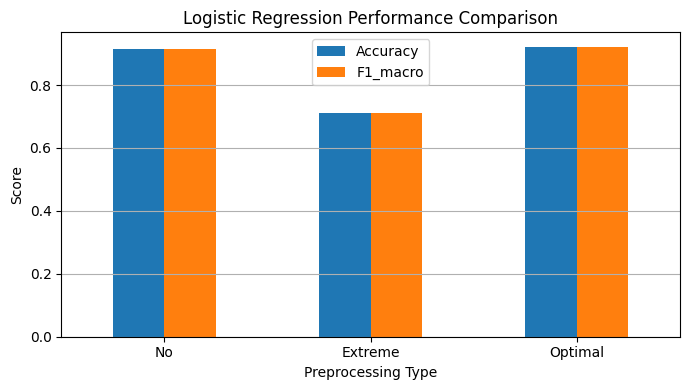

In [ ]:
# visualization

import matplotlib.pyplot as plt

ax = df_lr_pipeline.plot(kind='bar', figsize=(7,4))

plt.title("Logistic Regression Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Preprocessing Type")
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))
    plt.imshow(cm)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    # annotate values
    for i in range(len(cm)):
        for j in range(len(cm)):
            plt.text(j, i, cm[i, j], ha='center', va='center')

    plt.tight_layout()
    plt.show()

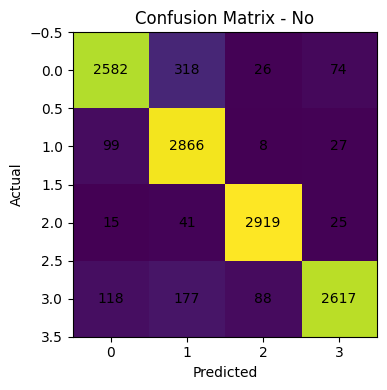

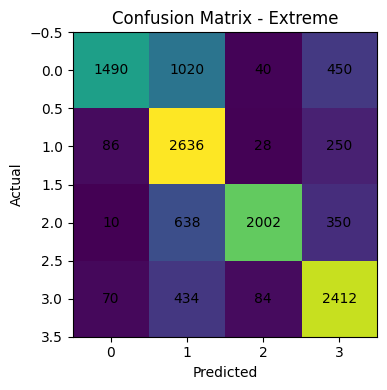

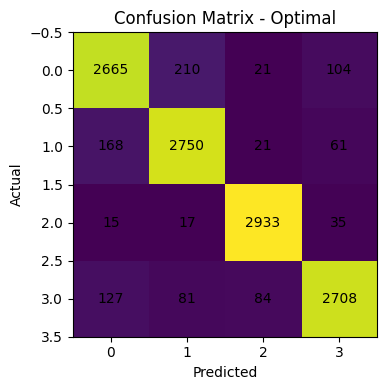

In [ ]:
for key in lr_predictions:
    y_true, y_pred = lr_predictions[key]
    plot_confusion_matrix(y_true, y_pred, f"Confusion Matrix - {key}")

The results indicate that optimal preprocessing yielded the best overall performance, though it outperformed the no preprocessing setting by only a slim margin. This suggests that the raw dataset is already relatively clean, requiring only minimal, targeted adjustments to reach peak accuracy. In contrast, extreme preprocessing caused a significant performance drop. This confirms that over-processing removes critical contextual information and 'useful noise' that the RNN relies on to distinguish between categories.

In [ ]:
df_no_prep["text"] = df_no_prep["headline"]
df_extreme["text"] = df_extreme["headline"].apply(extreme_clean)
df_optimal["text"] = df_optimal["headline"].apply(optimal_clean)

df_test["text"] = df_test["headline"]

## **TF-IDF + Deep Neural Network (DNN)**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

def run_dnn_pipeline(df_train_full, df_test, name):

    print(f"\n==============================")
    print(f" RUNNING DNN PIPELINE: {name}")
    print(f"==============================")

    df_train, df_val = train_test_split(
        df_train_full,
        test_size=0.2,
        random_state=42,
        stratify=df_train_full["topic"]
    )


    param_grid = [
        {"svd": 200, "epochs": 10, "batch": 128},
        {"svd": 300, "epochs": 15, "batch": 128},
        {"svd": 300, "epochs": 20, "batch": 64},
    ]

    results = []


    for params in param_grid:

        print(f"\nTesting Params: {params}")

        # TF-IDF
        from sklearn.feature_extraction.text import TfidfVectorizer
        tfidf = TfidfVectorizer(ngram_range=(1,2), max_df=0.9, min_df=5)

        X_train = tfidf.fit_transform(df_train["text"])
        X_val = tfidf.transform(df_val["text"])

        # SVD
        from sklearn.decomposition import TruncatedSVD
        svd = TruncatedSVD(n_components=params["svd"])
        X_train_svd = svd.fit_transform(X_train)
        X_val_svd = svd.transform(X_val)

        # Labels
        from sklearn.preprocessing import LabelEncoder
        from tensorflow.keras.utils import to_categorical

        le = LabelEncoder()
        y_train_enc = le.fit_transform(df_train["topic"])
        y_val_enc = le.transform(df_val["topic"])

        y_train_cat = to_categorical(y_train_enc)

        # Model
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import Dense, Dropout

        model = Sequential([
            Dense(256, activation='relu', input_shape=(X_train_svd.shape[1],)),
            Dropout(0.5),
            Dense(128, activation='relu'),
            Dropout(0.5),
            Dense(64, activation='relu'),
            Dense(y_train_cat.shape[1], activation='softmax')
        ])

        model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

        model.fit(
            X_train_svd, y_train_cat,
            epochs=params["epochs"],
            batch_size=params["batch"],
            verbose=0
        )

        # Validation prediction
        y_pred = model.predict(X_val_svd).argmax(axis=1)

        acc = accuracy_score(y_val_enc, y_pred)
        f1 = f1_score(y_val_enc, y_pred, average='macro')

        print(f"Validation Acc: {acc:.4f}, F1: {f1:.4f}")

        results.append((params, acc, f1))


    best_params = sorted(results, key=lambda x: x[2], reverse=True)[0][0]

    print("\n BEST PARAMS:", best_params)

    from sklearn.feature_extraction.text import TfidfVectorizer
    tfidf = TfidfVectorizer(ngram_range=(1,2), max_df=0.9, min_df=5)

    X_train_full = tfidf.fit_transform(df_train_full["text"])
    X_test = tfidf.transform(df_test["text"])

    from sklearn.decomposition import TruncatedSVD
    svd = TruncatedSVD(n_components=best_params["svd"])

    X_train_full = svd.fit_transform(X_train_full)
    X_test = svd.transform(X_test)

    # Labels
    from sklearn.preprocessing import LabelEncoder
    from tensorflow.keras.utils import to_categorical

    le = LabelEncoder()
    y_train_enc = le.fit_transform(df_train_full["topic"])
    y_test_enc = le.transform(df_test["topic"])

    y_train_cat = to_categorical(y_train_enc)

    # Model
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout

    model = Sequential([
        Dense(256, activation='relu', input_shape=(X_train_full.shape[1],)),
        Dropout(0.5),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(64, activation='relu'),
        Dense(y_train_cat.shape[1], activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    model.fit(
        X_train_full, y_train_cat,
        epochs=best_params["epochs"],
        batch_size=best_params["batch"],
        verbose=1
    )

    y_pred = model.predict(X_test).argmax(axis=1)

    acc = accuracy_score(y_test_enc, y_pred)
    f1 = f1_score(y_test_enc, y_pred, average='macro')

    print("\n FINAL TEST RESULTS")
    print("Accuracy:", acc)
    print("F1:", f1)

    print("\nClassification Report:\n", classification_report(y_test_enc, y_pred))

    return acc, f1, y_test_enc, y_pred, le

In [ ]:
dnn_results_final = {}
dnn_results_final["No"] = run_dnn_pipeline(df_no_prep, df_test, "No Prep")
dnn_results_final["Extreme"] = run_dnn_pipeline(df_extreme, df_test, "Extreme")
dnn_results_final["Optimal"] = run_dnn_pipeline(df_optimal, df_test, "Optimal")


 RUNNING DNN PIPELINE: No Prep

Testing Params: {'svd': 200, 'epochs': 10, 'batch': 128}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


661/661 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Acc: 0.9025, F1: 0.8970

Testing Params: {'svd': 300, 'epochs': 15, 'batch': 128}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


661/661 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Acc: 0.9146, F1: 0.9099

Testing Params: {'svd': 300, 'epochs': 20, 'batch': 64}


...

660/660 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Acc: 0.9032, F1: 0.8986

Testing Params: {'svd': 300, 'epochs': 20, 'batch': 64}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


660/660 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Acc: 0.9087, F1: 0.9038

 BEST PARAMS: {'svd': 300, 'epochs': 20, 'batch': 64}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8338 - loss: 0.4546
Epoch 2/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8787 - loss: 0.3452
Epoch 3/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8860 - loss: 0.3222
Epoch 4/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8907 - loss: 0.3040
Epoch 5/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8959 - loss: 0.2902
Epoch 6/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9000 - loss: 0.2783
Epoch 7/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9040 - loss: 0.2682
Epoch 8/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9067 - loss: 0.2611
Epoch 9/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9090 - loss: 0.2535
Epoch 10/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9119 - loss: 0.2451
Epoch 11/20
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9127 - loss: 0.2405
Epoch 12/20
1648/1648 ━━━━━━━━

In [ ]:
import pandas as pd

rows = []

for name, values in dnn_results_final.items():

    acc = values[0]
    f1 = values[1]

    rows.append([name, acc, f1])

df_dnn_final = pd.DataFrame(rows, columns=[
    "Preprocessing", "Accuracy", "F1_macro"
])

df_dnn_final = df_dnn_final.set_index("Preprocessing")

print("\n===== DNN FINAL RESULTS TABLE =====")
print(df_dnn_final.round(4))


===== DNN FINAL RESULTS TABLE =====
               Accuracy  F1_macro
Preprocessing                    
No               0.9032    0.9033
Extreme          0.7326    0.7337
Optimal          0.9005    0.9006


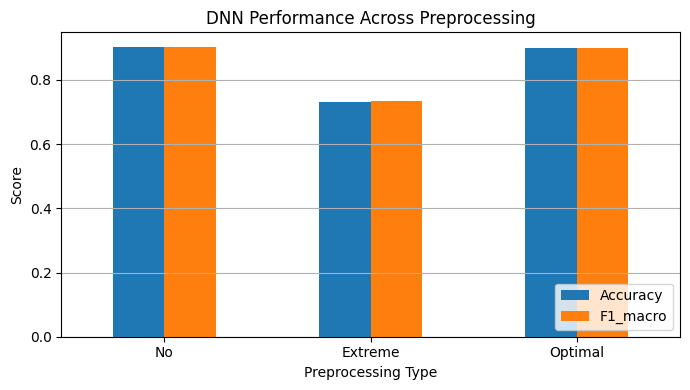

In [ ]:
# visualization
import matplotlib.pyplot as plt

df_dnn_final.plot(kind='bar', figsize=(7,4))

plt.title("DNN Performance Across Preprocessing")
plt.ylabel("Score")
plt.xlabel("Preprocessing Type")
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_cm(y_true, y_pred, le, title):

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )

    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


===== No CONFUSION MATRIX =====


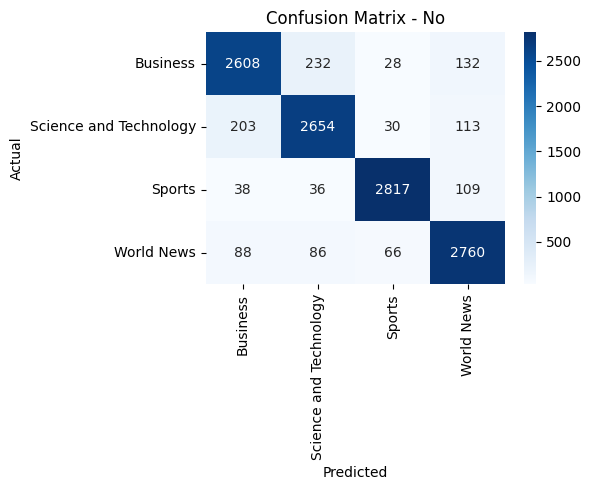


===== Extreme CONFUSION MATRIX =====


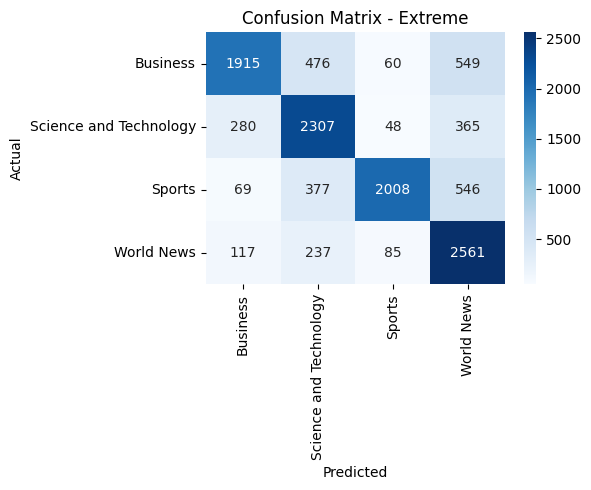


===== Optimal CONFUSION MATRIX =====


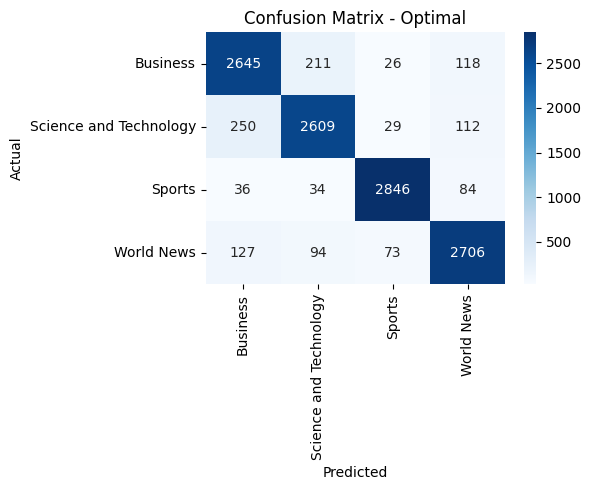

In [ ]:
for name, result in dnn_results_final.items():

    acc, f1, y_true, y_pred, le = result

    print(f"\n===== {name} CONFUSION MATRIX =====")
    plot_cm(y_true, y_pred, le, name)

The matrices highlight how different preprocessing intensities affect the models ability to distinguish between news categories:

Optimal Preprocessing (Highest Precision): Features the strongest diagonal, with Sports achieving the highest true positive count (2846). This confirms that balanced cleaning provides the clearest signal for the RNN.

No Preprocessing (Strong Resilience): Shows surprisingly high performance across all classes, indicating the model can effectively ignore raw noise (punctuation, tags) without a significant loss in accuracy.

Extreme Preprocessing (High Confusion): Results in a major performance drop. Misclassifications spike, particularly with Business and Sports being incorrectly labeled as World News (549 and 546 times, respectively).

# **Training Skipgram**

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 72.4 MB/s eta 0:00:00


In [ ]:
df_embed = df_no_prep
df_embed1 = df_extreme
df_embed2 = df_optimal

The skip-gram embeddings show clear and coherent semantic clustering across different domains, indicating that the model successfully learned meaningful contextual relationships between words. A small amount of noise, such as rare or low-frequency tokens like “9boi,” “ofgem,” and “upa,” is still present, but these have minimal impact on the overall representation quality and downstream model performance due to their limited occurrence.

# **RNN Models**

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

    df = df.copy()
    if "text" not in df.columns:
        df["text"] = df["headline"]
    return df


    sentences = df["text"].apply(lambda x: x.split()).tolist()

    from gensim.models import Word2Vec

    model = Word2Vec(
        sentences,
        vector_size=100,
        window=5,
        min_count=5,
        sg=1,
        workers=4,
        epochs=10
    )

    return model


def prepare_data(df, w2v_model):

    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    import numpy as np

    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(df["text"])

    sequences = tokenizer.texts_to_sequences(df["text"])
    X_seq = pad_sequences(sequences, maxlen=100)

    word_index = tokenizer.word_index

    embedding_matrix = np.zeros((len(word_index)+1, 100))

    for word, i in word_index.items():
        if word in w2v_model.wv:
            embedding_matrix[i] = w2v_model.wv[word]

    return X_seq, word_index, embedding_matrix, tokenizer


def prepare_labels(df):

    from sklearn.preprocessing import LabelEncoder
    from tensorflow.keras.utils import to_categorical

    le = LabelEncoder()
    y_enc = le.fit_transform(df["topic"])
    y_cat = to_categorical(y_enc)

    return y_cat, le


def build_model(model_type, bidirectional, units, X_train, y_train, embedding_matrix, word_index):

    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, Dense, Dropout, SimpleRNN, GRU, LSTM, Bidirectional

    model = Sequential()

    model.add(Embedding(
        input_dim=len(word_index)+1,
        output_dim=100,
        weights=[embedding_matrix],
        trainable=False,
        input_length=X_train.shape[1]
    ))

    if model_type == "RNN":
        layer = SimpleRNN(units)
    elif model_type == "GRU":
        layer = GRU(units)
    else:
        layer = LSTM(units)

    if bidirectional:
        model.add(Bidirectional(layer))
    else:
        model.add(layer)

    model.add(Dropout(0.5))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(y_train.shape[1], activation='softmax'))

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    return model



def run_rnn_pipeline(df_train_full, df_test, name):

    print(f"\n==============================")
    print(f" RUNNING RNN PIPELINE: {name}")
    print(f"==============================")

    # FIX TEXT
    df_train_full = ensure_text(df_train_full)
    df_test = ensure_text(df_test)

    # SPLIT
    df_train, df_val = train_test_split(
        df_train_full,
        test_size=0.2,
        random_state=42,
        stratify=df_train_full["topic"]
    )


    w2v_model = train_w2v(df_train_full)

    # DATA PREP
    X_seq, word_index, embedding_matrix, tokenizer = prepare_data(df_train_full, w2v_model)
    y_cat, le = prepare_labels(df_train_full)

    # TRAIN/VAL SPLIT FOR TUNING
    X_train, X_val, y_train, y_val = train_test_split(
        X_seq, y_cat, test_size=0.2, random_state=42
    )


    param_grid = [
        {"model": "GRU", "bidir": False, "units": 128, "epochs": 10, "batch": 128},
        {"model": "GRU", "bidir": True,  "units": 128, "epochs": 10, "batch": 128},
        {"model": "LSTM", "bidir": False, "units": 128, "epochs": 10, "batch": 128},
        {"model": "LSTM", "bidir": True,  "units": 128, "epochs": 15, "batch": 128},
        {"model": "GRU", "bidir": False, "units": 256, "epochs": 15, "batch": 64},
    ]

    results = []

    for p in param_grid:

        print(f"\nTesting: {p}")

        model = build_model(
            p["model"],
            p["bidir"],
            p["units"],
            X_train,
            y_train,
            embedding_matrix,
            word_index
        )

        model.fit(
            X_train,
            y_train,
            epochs=p["epochs"],
            batch_size=p["batch"],
            verbose=0
        )

        val_pred = model.predict(X_val).argmax(axis=1)
        val_true = y_val.argmax(axis=1)

        acc = accuracy_score(val_true, val_pred)
        f1 = f1_score(val_true, val_pred, average='macro')

        print(f"Validation → Acc: {acc:.4f}, F1: {f1:.4f}")

        results.append((p, acc, f1))


    best_params = sorted(results, key=lambda x: x[2], reverse=True)[0][0]

    print("\n BEST PARAMS:", best_params)


    model = build_model(
        best_params["model"],
        best_params["bidir"],
        best_params["units"],
        X_seq,
        y_cat,
        embedding_matrix,
        word_index
    )

    model.fit(
        X_seq,
        y_cat,
        epochs=best_params["epochs"],
        batch_size=best_params["batch"],
        verbose=1
    )

    sequences = tokenizer.texts_to_sequences(df_test["text"])

    from tensorflow.keras.preprocessing.sequence import pad_sequences
    X_test = pad_sequences(sequences, maxlen=100)

    y_test_enc = le.transform(df_test["topic"])

    y_pred = model.predict(X_test).argmax(axis=1)

    acc = accuracy_score(y_test_enc, y_pred)
    f1 = f1_score(y_test_enc, y_pred, average='macro')

    print("\n FINAL TEST RESULTS")
    print("Accuracy:", acc)
    print("F1:", f1)

    return acc, f1, y_test_enc, y_pred, le

In [ ]:
rnn_results = {}

rnn_results["No Preprocessing"] = run_rnn_pipeline(df_embed, df_test,  "No Preprocessing")

rnn_results["Extreme"] = run_rnn_pipeline(df_embed1, df_test, "Extreme")

rnn_results["Optimal"] = run_rnn_pipeline(df_embed2, df_test, "Optimal")


 RUNNING RNN PIPELINE: No Preprocessing

Testing: {'model': 'GRU', 'bidir': False, 'units': 128, 'epochs': 10, 'batch': 128}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


661/661 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
Validation → Acc: 0.9027, F1: 0.8995

Testing: {'model': 'GRU', 'bidir': True, 'units': 128, 'epochs': 10, 'batch': 128}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


661/661 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
Validation → Acc: 0.9038, F1: 0.9007

Testing: {'model': 'LSTM', 'bidir': False, 'units': 128, 'epochs': 10, 'batch': 128}


...

660/660 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
Validation → Acc: 0.9175, F1: 0.9170

Testing: {'model': 'GRU', 'bidir': False, 'units': 256, 'epochs': 15, 'batch': 64}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


660/660 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Validation → Acc: 0.9274, F1: 0.9242

 BEST PARAMS: {'model': 'GRU', 'bidir': False, 'units': 256, 'epochs': 15, 'batch': 64}
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


1648/1648 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.8754 - loss: 0.3539
Epoch 2/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8965 - loss: 0.2890
Epoch 3/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9057 - loss: 0.2596
Epoch 4/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9156 - loss: 0.2332
Epoch 5/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9249 - loss: 0.2094
Epoch 6/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9329 - loss: 0.1857
Epoch 7/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9402 - loss: 0.1659
Epoch 8/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9473 - loss: 0.1452
Epoch 9/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9542 - loss: 0.1269
Epoch 10/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9608 - loss: 0.1083
Epoch 11/15
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9655 - loss: 0.0956
Epoch 12/15
1648/16

In [ ]:
import pandas as pd

rows = []

for dataset, values in rnn_results.items():

    acc, f1, y_true, y_pred, le = values

    rows.append([dataset, "RNN/LSTM/GRU", acc, f1])

df_rnn_final = pd.DataFrame(rows, columns=[
    "Dataset", "Model", "Accuracy", "F1_macro"
])

print("\n===== RNN FINAL COMPARISON TABLE =====")
print(df_rnn_final.round(4))


===== RNN FINAL COMPARISON TABLE =====
            Dataset         Model  Accuracy  F1_macro
0  No Preprocessing  RNN/LSTM/GRU    0.8915    0.8920
1           Extreme  RNN/LSTM/GRU    0.5858    0.5882
2           Optimal  RNN/LSTM/GRU    0.9118    0.9119


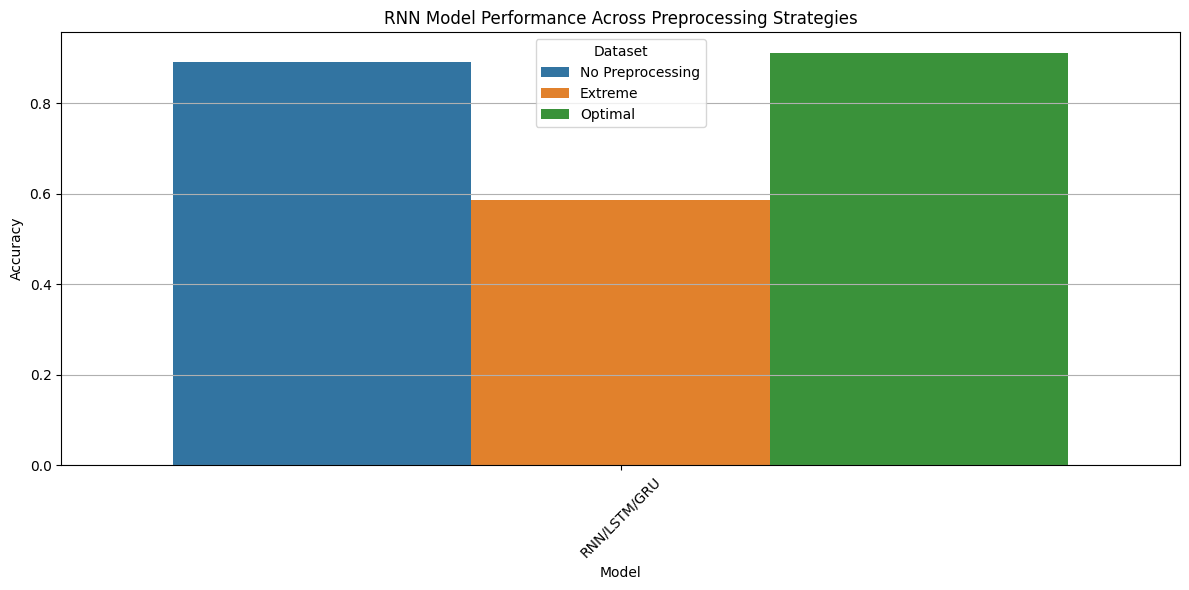

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.barplot(
    data=df_rnn_final,
    x="Model",
    y="Accuracy",
    hue="Dataset"
)

plt.title("RNN Model Performance Across Preprocessing Strategies")
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()


===== No Preprocessing =====


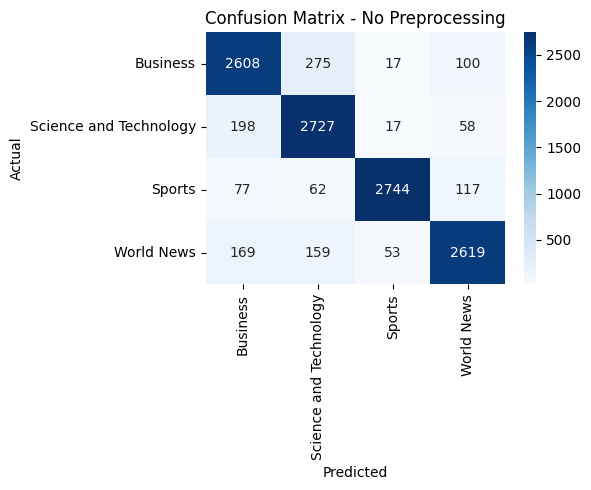


===== Extreme =====


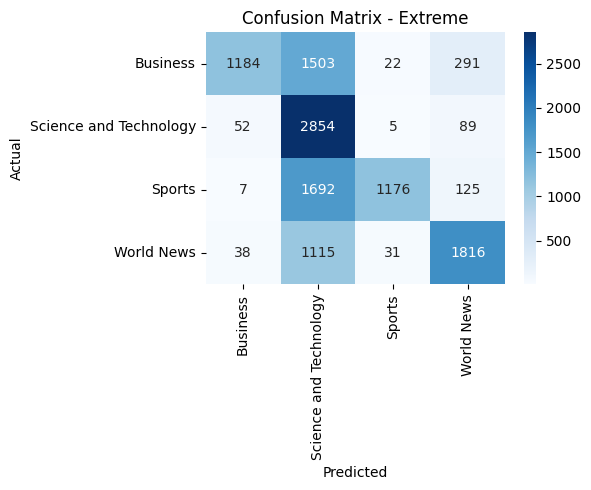


===== Optimal =====


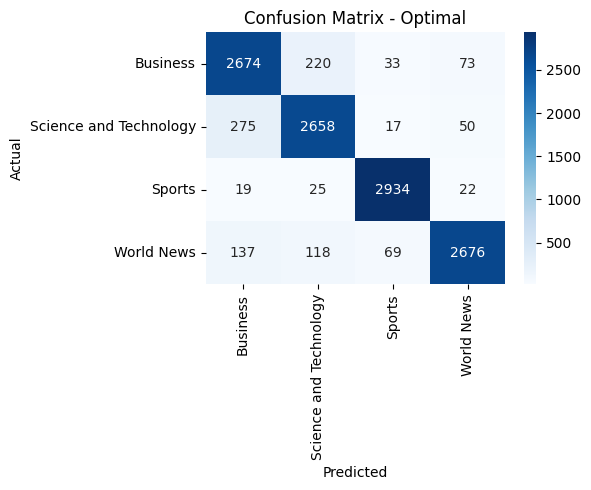

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion_matrix(y_true, y_pred, le, title):

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )

    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


for dataset, values in rnn_results.items():

    acc, f1, y_true, y_pred, le = values

    print(f"\n===== {dataset} =====")

    plot_confusion_matrix(
        y_true,
        y_pred,
        le,
        dataset
    )

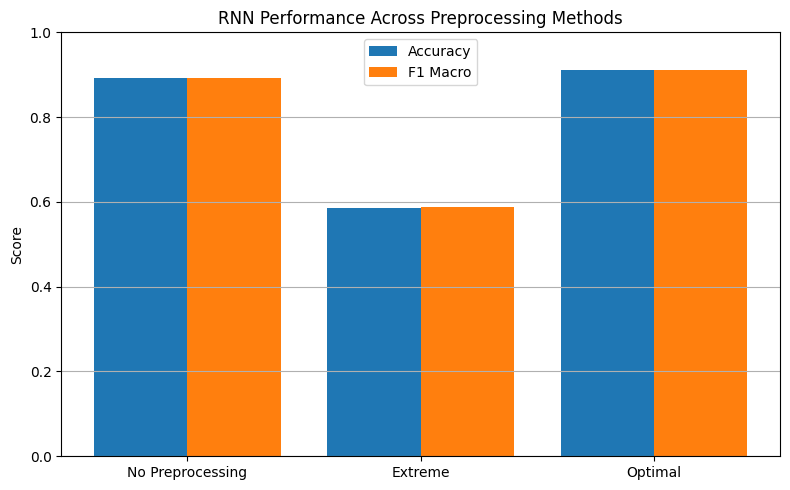

In [ ]:
import matplotlib.pyplot as plt

datasets = list(rnn_results.keys())
accuracy = [rnn_results[d][0] for d in datasets]
f1_scores = [rnn_results[d][1] for d in datasets]

x = range(len(datasets))

plt.figure(figsize=(8,5))

plt.bar(x, accuracy, width=0.4, label="Accuracy")
plt.bar([i + 0.4 for i in x], f1_scores, width=0.4, label="F1 Macro")

plt.xticks([i + 0.2 for i in x], datasets, rotation=0)
plt.ylim(0, 1)

plt.title("RNN Performance Across Preprocessing Methods")
plt.ylabel("Score")
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()

Optimal Preprocessing: This method yields the highest performance, with both Accuracy and F1 Macro scores exceeding 0.9 (90%). This indicates that a balanced approach to data cleaning—removing noise while retaining essential linguistic structure—allows the RNN to learn the most effective representations.

No Preprocessing: Surprisingly, leaving the data in its raw state performs remarkably well, achieving scores just under 0.9. This suggests that the RNN (likely using robust embeddings) can manage a certain degree of noise, such as punctuation or HTML tags, without a catastrophic loss in predictive power.

Extreme Preprocessing: This method results in the lowest performance by a significant margin, with scores dropping to approximately 0.6 (60%). The sharp decline indicates that "over-cleaning" the data likely removed critical contextual markers or tokens necessary for the model to understand the sequence.

# **Final Comparison**

When comparing all three models across different preprocessing strategies, a clear pattern emerges. Logistic Regression achieved the strongest overall performance, with its best result coming from the optimal preprocessing pipeline, reaching an accuracy of approximately 92.13% and a similar macro F1-score. The Deep Neural Network performed slightly lower, with its best result appearing under no preprocessing at around 90.33%, while the optimal preprocessing version followed very closely. The RNN-based models, which used Word2Vec embeddings, showed competitive performance but did not surpass Logistic Regression; their best configuration under optimal preprocessing achieved about 91.18% accuracy. A consistent and important observation across all models is that extreme preprocessing significantly reduced performance, dropping accuracy as low as 58% in the RNN case. This indicates that overly aggressive text cleaning removed useful contextual and semantic information necessary for classification. Overall, the results demonstrate that a balanced preprocessing strategy is crucial, and that traditional models like Logistic Regression, when combined with well-tuned TF-IDF features, can outperform more complex deep learning approaches in structured text classification tasks.